# Simple Linear Regression

Simple linear regression draws the one straight line that sits closest to all the points. Here it predicts a car's fuel economy (**mpg**) from its **weight**.

This notebook goes with the **Simple Linear Regression** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

**The steps:** load the data → split into train and test → fit the line → check the result → draw it.

## 1. Load the data

Each row is a car from the late 1970s and early 1980s. We want to predict `mpg` (miles per gallon) from `weight` (in pounds).

The data is the [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) data set from the UCI Machine Learning Repository (CC BY 4.0). See `datasets/README.md` for what we changed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/mpg.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,18.0,8,307.0,130.0,3504,12.0,70,usa
1,15.0,8,350.0,165.0,3693,11.5,70,usa
2,18.0,8,318.0,150.0,3436,11.0,70,usa
3,16.0,8,304.0,150.0,3433,12.0,70,usa
4,17.0,8,302.0,140.0,3449,10.5,70,usa


In [2]:
X = dataset[['weight']].values   # one input column, kept 2-D because scikit-learn expects rows x columns
y = dataset['mpg'].values
print(X.shape, 'cars')

(398, 1) cars


## 2. Split into train and test

The model learns from the **training** cars (75%). We hold back the other 25% and only use them at the end. The test score shows how the model does on cars it has never seen. These are the ringed points on the site's boards.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

298 train, 100 test


## 3. Fit the line

`LinearRegression` finds the slope and intercept that make the total squared miss as small as possible (least squares). No scaling is needed for a single input.

In [4]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print('slope:', regressor.coef_[0], 'mpg per pound')
print('intercept:', round(regressor.intercept_, 2))

slope: -0.007616653565924857 mpg per pound
intercept: 46.09


## 4. Check the result

**R²** says how much of the ups and downs in the data the model explains. 1 is perfect, 0 is no better than always guessing the average. The number that matters is the **test** R². The last line shows the typical miss in miles per gallon.

In [5]:
y_pred_train = regressor.predict(X_train)
y_pred_test = regressor.predict(X_test)
print('Train R²:', round(r2_score(y_train, y_pred_train), 3))
print('Test R²: ', round(r2_score(y_test, y_pred_test), 3))
print('Test error on average:', round(mean_absolute_error(y_test, y_pred_test), 2), 'mpg')

Train R²: 0.683
Test R²:  0.718
Test error on average: 3.34 mpg


## 5. Draw it

Filled dots are training cars, ringed dots are test cars, and the line is the model. The short vertical lines are the **residuals**: how far each test car is from the line.

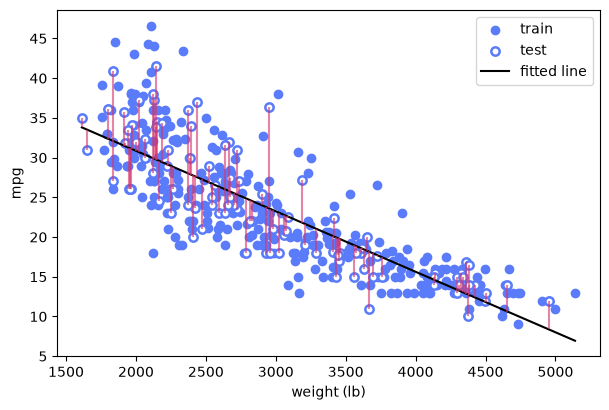

In [6]:
grid = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color='#5b7cfa', label='train')
plt.scatter(X_test, y_test, facecolors='white', edgecolors='#5b7cfa', linewidths=1.8, label='test')
plt.plot(grid, regressor.predict(grid), color='black', label='fitted line')
plt.vlines(X_test.ravel(), y_test, y_pred_test, color='#d6336c', alpha=0.6)
plt.xlabel('weight (lb)'); plt.ylabel('mpg'); plt.legend()
plt.show()

## Try this

1. Predict the mpg of a 3000 lb car: `regressor.predict([[3000]])`.
2. Change `random_state=0` to another number. The slope barely moves, but the test R² changes. Why?
3. Replace `weight` with `horsepower` (drop the rows without a value first). Which input predicts mpg better?

## See it: the fit and the misses

**Left:** the fitted straight line through the cars. Filled dots are training cars and ringed dots are test cars. The test R² is in the title. **Right:** the residuals, which are the misses (actual mpg minus predicted mpg). **Notice how** a good fit leaves residuals scattered evenly around 0 with no pattern. A straight line cannot bend, so any curve in the data shows up as a pattern in the residuals.

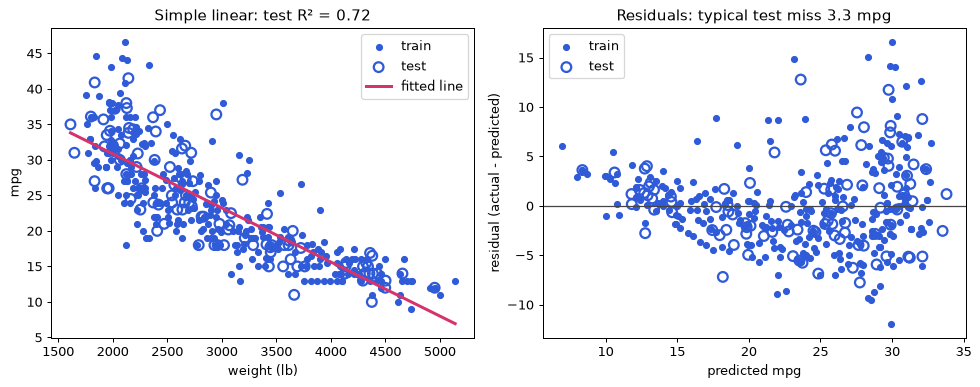

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

def model_predict(X_raw):
    return regressor.predict(X_raw)

xs = X[:, :1]
fit_x = np.linspace(xs.min(), xs.max(), 300).reshape(-1, 1)
yt, yte = np.ravel(y_train), np.ravel(y_test)
p_tr, p_te = model_predict(X_train), model_predict(X_test)
r2 = r2_score(yte, p_te)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.scatter(X_train[:, 0], yt, color=BLUE, s=22, label='train')
ax1.scatter(X_test[:, 0], yte, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax1.plot(fit_x[:, 0], model_predict(fit_x), color=PINK, linewidth=2.4, label='fitted line')
ax1.set_xlabel('weight (lb)'); ax1.set_ylabel('mpg')
ax1.set_title(f'Simple linear: test R² = {r2:.2f}')
ax1.legend()

ax2.axhline(0, color='#444444', linewidth=1)
ax2.scatter(p_tr, yt - p_tr, color=BLUE, s=22, label='train')
ax2.scatter(p_te, yte - p_te, facecolors='none', edgecolors=BLUE, s=60, linewidths=1.8, label='test')
ax2.set_xlabel('predicted mpg'); ax2.set_ylabel('residual (actual - predicted)')
ax2.set_title(f'Residuals: typical test miss {np.abs(yte - p_te).mean():.1f} mpg')
ax2.legend()
fig.tight_layout()
plt.show()
